# ĐỀ TÀI 5 - PHẦN A.3, C.2, C.3, C.4 (VINH)
Hướng dẫn chạy trên Google Colab:
1. Tải tệp `ensemble_boosting.py` lên thư mục gốc của Colab (bấm biểu tượng thư mục bên trái -> Upload).
2. Chọn **Runtime -> Run all** để chạy toàn bộ, đối chiếu kết quả và tải các hình `.png` về.

In [2]:
!pip install -q shap scikit-learn matplotlib pandas numpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import fetch_california_housing
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, accuracy_score
import shap

from ensemble_boosting import AdaBoostClassifierCustom, GradientBoostingRegressorCustom
print('Import thành công!')

Import thành công!


## 1. Kiểm chứng A.3 với thư viện Scikit-Learn (AdaBoost & Gradient Boosting MSE/Huber)

In [3]:
# Kiểm chứng Gradient Boosting tự cài đặt so với sklearn
rng = np.random.default_rng(42)
X_syn = rng.uniform(-3, 3, size=(300, 4))
y_syn = 2.5 * np.sin(X_syn[:, 0]) + 1.5 * X_syn[:, 1]**2 - X_syn[:, 2] + rng.normal(0, 0.3, size=300)

gb_custom_mse = GradientBoostingRegressorCustom(n_estimators=80, learning_rate=0.1, max_depth=3, loss='mse', random_state=42)
gb_custom_mse.fit(X_syn, y_syn)

gb_sk_mse = GradientBoostingRegressor(n_estimators=80, learning_rate=0.1, max_depth=3, loss='squared_error', random_state=42)
gb_sk_mse.fit(X_syn, y_syn)

diff_mse = np.max(np.abs(gb_custom_mse.predict(X_syn) - gb_sk_mse.predict(X_syn)))
print(f'Sai lệch dự đoán lớn nhất (GB MSE custom vs sklearn): {diff_mse:.2e}')

# Kiểm chứng Huber với dữ liệu có nhiễu ngoại lai
y_outlier = y_syn.copy()
y_outlier[:15] += 25.0
gb_custom_huber = GradientBoostingRegressorCustom(n_estimators=80, learning_rate=0.1, max_depth=3, loss='huber', alpha=0.9, subsample=0.8, random_state=42)
gb_custom_huber.fit(X_syn, y_outlier)
rmse_clean_mse = np.sqrt(mean_squared_error(y_syn, GradientBoostingRegressorCustom(n_estimators=80, loss='mse').fit(X_syn, y_outlier).predict(X_syn)))
rmse_clean_huber = np.sqrt(mean_squared_error(y_syn, gb_custom_huber.predict(X_syn)))
print(f'RMSE trên nhãn sạch khi huấn luyện có outlier - MSE: {rmse_clean_mse:.4f} vs Huber: {rmse_clean_huber:.4f}')

Sai lệch dự đoán lớn nhất (GB MSE custom vs sklearn): 3.55e-15
RMSE trên nhãn sạch khi huấn luyện có outlier - MSE: 3.9426 vs Huber: 1.6765


## 2. Bài tập C.2: Đối chiếu code AdaBoost trên 10 mẫu với kết quả tính tay

In [4]:
X_c2 = np.arange(1, 11).reshape(-1, 1)
y_c2 = np.array([1, 1, 1, -1, -1, -1, 1, 1, 1, -1])

ada_custom = AdaBoostClassifierCustom(n_estimators=3)
ada_custom.fit(X_c2, y_c2)

for t in range(3):
    stump = ada_custom.estimators_[t]
    eps = ada_custom.estimator_errors_[t]
    alpha = ada_custom.estimator_weights_[t]
    err_train = ada_custom.train_error_history_[t]
    w_next = np.round(ada_custom.weight_history_[t+1], 4)
    print(f'=== Vòng t = {t+1} ===')
    print(f'Ngưỡng cắt: {stump.threshold}, Polarity: {stump.polarity}')
    print(f'epsilon_{t+1} = {eps:.4f} | alpha_{t+1} = {alpha:.4f} | Sai số huấn luyện = {err_train:.2f}')
    print(f'Phân phối trọng số D_{t+2}: {w_next}\n')

# Đối chiếu với sklearn AdaBoost
ada_sk = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=3,
    algorithm='SAMME',
    random_state=42
)
ada_sk.fit(X_c2, y_c2)
print('Dự đoán custom :', ada_custom.predict(X_c2))
print('Dự đoán sklearn:', ada_sk.predict(X_c2))
print('Trọng số alpha sklearn:', np.round(ada_sk.estimator_weights_, 4))

=== Vòng t = 1 ===
Ngưỡng cắt: 3.5, Polarity: 1
epsilon_1 = 0.3000 | alpha_1 = 0.4236 | Sai số huấn luyện = 0.30
Phân phối trọng số D_2: [0.0714 0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714]

=== Vòng t = 2 ===
Ngưỡng cắt: 9.5, Polarity: 1
epsilon_2 = 0.2143 | alpha_2 = 0.6496 | Sai số huấn luyện = 0.30
Phân phối trọng số D_3: [0.0455 0.0455 0.0455 0.1667 0.1667 0.1667 0.1061 0.1061 0.1061 0.0455]

=== Vòng t = 3 ===
Ngưỡng cắt: 6.5, Polarity: -1
epsilon_3 = 0.1818 | alpha_3 = 0.7520 | Sai số huấn luyện = 0.00
Phân phối trọng số D_4: [0.125  0.125  0.125  0.1019 0.1019 0.1019 0.0648 0.0648 0.0648 0.125 ]

Dự đoán custom : [ 1.  1.  1. -1. -1. -1.  1.  1.  1. -1.]
Dự đoán sklearn: [ 1  1  1 -1 -1 -1  1  1  1 -1]
Trọng số alpha sklearn: [0.8473 1.2993 1.5041]


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


## 3. Bài tập C.3: Thêm biến ngẫu nhiên nhiều giá trị phân biệt (ID) — So sánh Impurity, Permutation & SHAP

            Impurity (MDI)  Permutation  SHAP (mean |SHAP|)
Random_ID           0.0257       0.0108              0.0171
AveBedrms           0.0289       0.0151              0.0194
Population          0.0354       0.0187              0.0221
AveRooms            0.0467       0.0248              0.0328
HouseAge            0.0569       0.0468              0.0602
Longitude           0.0655       0.0835              0.1094
Latitude            0.0697       0.1207              0.1329
AveOccup            0.1391       0.1406              0.1737
MedInc              0.5323       0.5390              0.4323


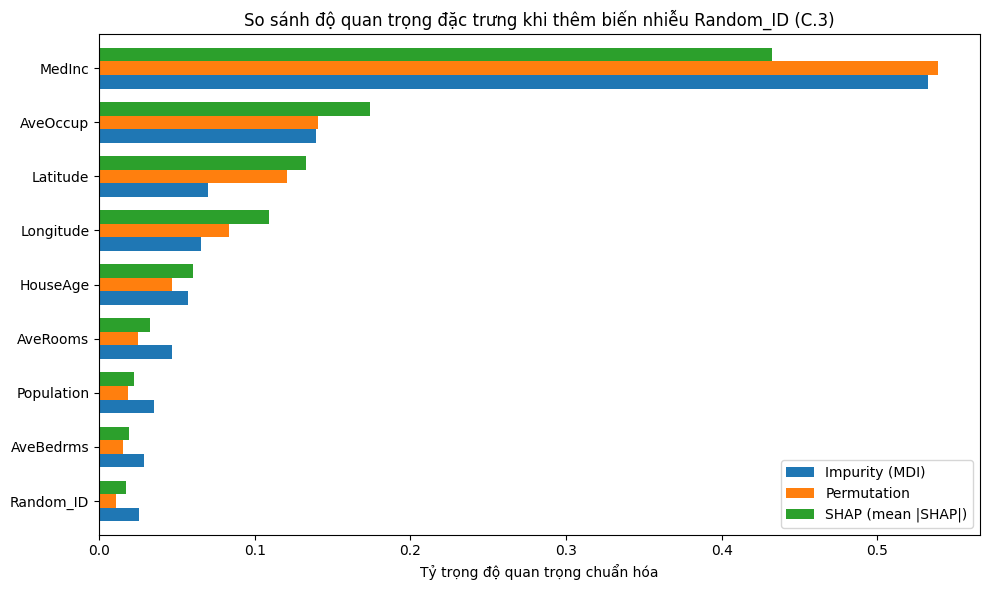

In [5]:
housing = fetch_california_housing(as_frame=True)
df_c3 = housing.frame.sample(n=1500, random_state=42).reset_index(drop=True)
X_c3 = df_c3.drop(columns=['MedHouseVal']).copy()
y_c3 = df_c3['MedHouseVal'].values

# Thêm biến ngẫu nhiên có nhiều giá trị phân biệt (Random_ID)
rng_c3 = np.random.default_rng(42)
X_c3['Random_ID'] = rng_c3.permutation(np.arange(len(X_c3)))

rf_c3 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_c3.fit(X_c3, y_c3)

# 1. Impurity-based importance (MDI)
imp_mdi = pd.Series(rf_c3.feature_importances_, index=X_c3.columns)

# 2. Permutation importance
perm_res = permutation_importance(rf_c3, X_c3, y_c3, n_repeats=10, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm_res.importances_mean, index=X_c3.columns)

# 3. SHAP importance
explainer = shap.TreeExplainer(rf_c3)
shap_vals = explainer.shap_values(X_c3.iloc[:300])
imp_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=X_c3.columns)

# Chuẩn hóa về tổng = 1 để dễ so sánh trên cùng thang đo
df_imp = pd.DataFrame({
    'Impurity (MDI)': imp_mdi / imp_mdi.sum(),
    'Permutation': np.maximum(imp_perm, 0) / np.maximum(imp_perm, 0).sum(),
    'SHAP (mean |SHAP|)': imp_shap / imp_shap.sum()
}).sort_values('SHAP (mean |SHAP|)', ascending=True)

print(df_imp.round(4))

ax = df_imp.plot(kind='barh', figsize=(10, 6), width=0.75)
ax.set_title('So sánh độ quan trọng đặc trưng khi thêm biến nhiễu Random_ID (C.3)')
ax.set_xlabel('Tỷ trọng độ quan trọng chuẩn hóa')
plt.tight_layout()
plt.savefig('C3_feature_importance_comparison.png', dpi=300)
plt.show()

## 4. Bài tập C.4: Khảo sát sai số OOB theo số cây và đối chiếu với sai số Kiểm định chéo (CV)

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


   So_cay  OOB_MSE  CV_5Fold_MSE_Mean  CV_5Fold_MSE_Std
0      10   0.2546             0.1631            0.0404
1      20   0.1854             0.1593            0.0420
2      30   0.1714             0.1568            0.0435
3      50   0.1578             0.1525            0.0445
4      75   0.1563             0.1537            0.0464
5     100   0.1552             0.1538            0.0474
6     150   0.1509             0.1533            0.0485
7     200   0.1522             0.1526            0.0482
8     300   0.1503             0.1530            0.0485


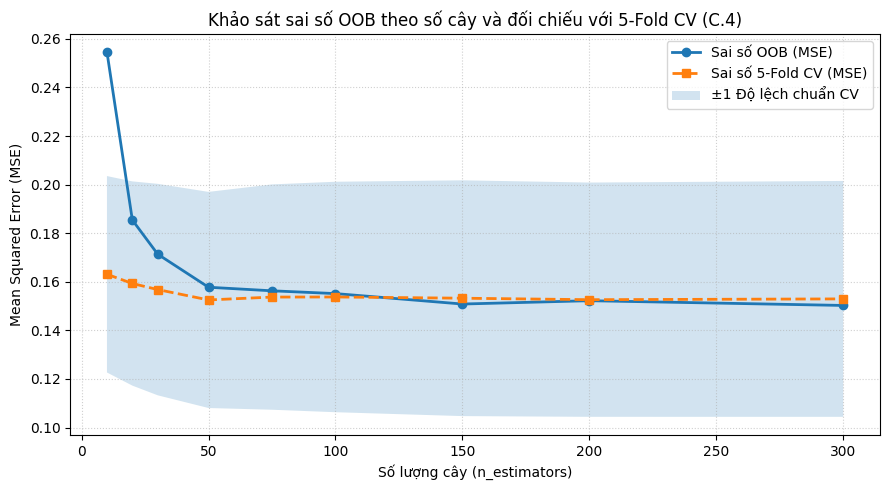

In [6]:
n_trees_list = [10, 20, 30, 50, 75, 100, 150, 200, 300]
oob_mse_list = []
cv_mse_mean = []
cv_mse_std = []

X_c4 = housing.data[:1500]
y_c4 = housing.target[:1500]
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for n_trees in n_trees_list:
    rf_oob = RandomForestRegressor(n_estimators=n_trees, oob_score=True, random_state=42, n_jobs=-1)
    rf_oob.fit(X_c4, y_c4)
    oob_mse = mean_squared_error(y_c4, rf_oob.oob_prediction_)
    oob_mse_list.append(oob_mse)

    rf_cv = RandomForestRegressor(n_estimators=n_trees, random_state=42, n_jobs=-1)
    scores = -cross_val_score(rf_cv, X_c4, y_c4, cv=kf, scoring='neg_mean_squared_error', n_jobs=-1)
    cv_mse_mean.append(scores.mean())
    cv_mse_std.append(scores.std())

df_c4 = pd.DataFrame({
    'So_cay': n_trees_list,
    'OOB_MSE': oob_mse_list,
    'CV_5Fold_MSE_Mean': cv_mse_mean,
    'CV_5Fold_MSE_Std': cv_mse_std
})
print(df_c4.round(4))

plt.figure(figsize=(9, 5))
plt.plot(n_trees_list, oob_mse_list, 'o-', label='Sai số OOB (MSE)', linewidth=2)
plt.plot(n_trees_list, cv_mse_mean, 's--', label='Sai số 5-Fold CV (MSE)', linewidth=2)
plt.fill_between(
    n_trees_list,
    np.array(cv_mse_mean) - np.array(cv_mse_std),
    np.array(cv_mse_mean) + np.array(cv_mse_std),
    alpha=0.2,
    label='±1 Độ lệch chuẩn CV'
)
plt.xlabel('Số lượng cây (n_estimators)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Khảo sát sai số OOB theo số cây và đối chiếu với 5-Fold CV (C.4)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('C4_oob_vs_cv.png', dpi=300)
plt.show()